# EDA Workflow

EDA stands for Exploratory Data Analysis in Machine Learning. It is the process of exploring, analyzing, and understanding a dataset before using it to train a machine learning model.

Think of EDA as investigating your data before teaching a machine to learn from it.

### 1. EDA workflow in Machine Learning



1. **Load the Dataset**: Read CSV, Excel, database, etc.

2. **Understand the Data**: Shape, columns, data types, sample rows

3. **Check Data Quality**: Missing values, duplicates, incorrect values

4. **Univariate Analysis**: Analyze individual features and their distributions

5. **Bivariate & Multivariate Analysis**: Explore relationships between features

6. **Detect Outliers & Patterns**: Find unusual observations, trends, and correlations

7. **Summarize Findings**: Decide what preprocessing and feature engineering are needed

### 2. Explain each step with Python
Let's use a simple employee salary dataset.

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 1. Load the dataset
The Seaborn library provides a Titanic dataset with 891 passengers and 15 columns, which is convenient for learning EDA.

In [ ]:
df = sns.load_dataset("titanic")

#### 2. Understand the dataset
Check its dimensions

In [6]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Inspect columns and data types

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [51]:
df.dtypes

survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object

In [52]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


What to look for:
- `age` and `fare` are numerical features.
- `sex`, `embarked`, and `class` are categorical features.
- `survived` is the target variable: 0 means the passenger did not survive, while 1 means the passenger survived.

#### 3. Check data quality
Missing values

In [59]:
df_missing = pd.DataFrame({
    'Missing Count' : df.isnull().sum(),
    'Missing Percentage' : (df.isnull().mean() * 100).round(2)
})

df_missing[df_missing['Missing Count'] > 0].sort_values(
    'Missing Count', ascending=False
)

,Missing Count,Missing Percentage
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


What does this tell us?
- `deck` has too many missing values to use straightforwardly. We should investigate whether it is useful before deciding what to do with it.
- `age` has enough missing values to require a deliberate strategy, such as imputing within relevant groups.
- `embarked` has only two missing values, so these are relatively easy to address.

Don't fill or delete anything yet. First understand the data.

In [60]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 107


#### 4. Univariate analysis
Univariate analysis means studying one variable at a time.

A. Survival distribution

In [63]:
print(df['survived'].value_counts())

survived
0    549
1    342
Name: count, dtype: int64


In [69]:
print((df['survived'].value_counts(normalize=True) * 100).round(2))

survived
0    61.62
1    38.38
Name: proportion, dtype: float64


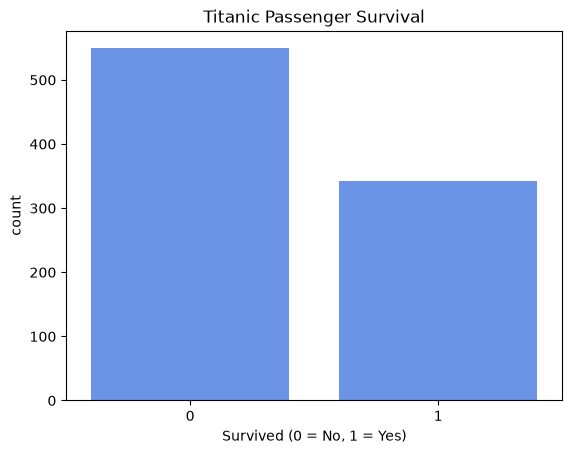

In [66]:
sns.countplot(data=df, x="survived")
plt.title("Titanic Passenger Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

B. Passenger age distribution

In [71]:
print(df["age"].describe())

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64


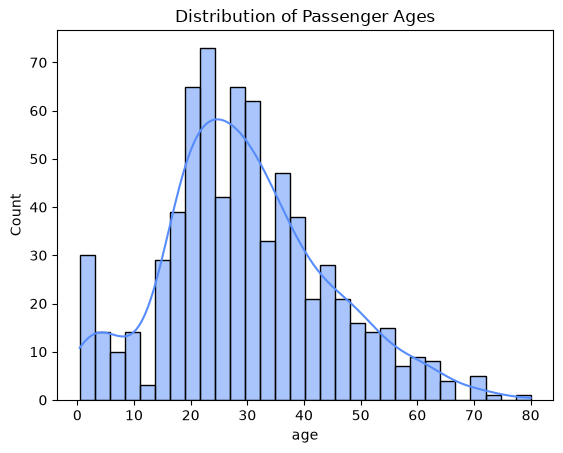

In [72]:
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Distribution of Passenger Ages")
plt.show()

Questions to investigate:
- What is the average age?
- What is the age range?
- Are there many children?
- Is the age distribution skewed?

Remember that 177 age values are missing, so the age statistics are calculated only from the available ages.

C. Passenger class distribution

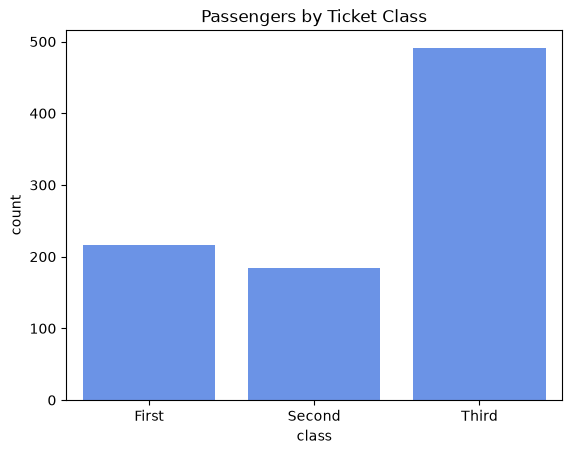

In [73]:
sns.countplot(data=df, x="class")
plt.title("Passengers by Ticket Class")
plt.show()

The three classes are First, Second, and Third. Compare the number of passengers in each class to understand the dataset's composition.

D. Fare distribution

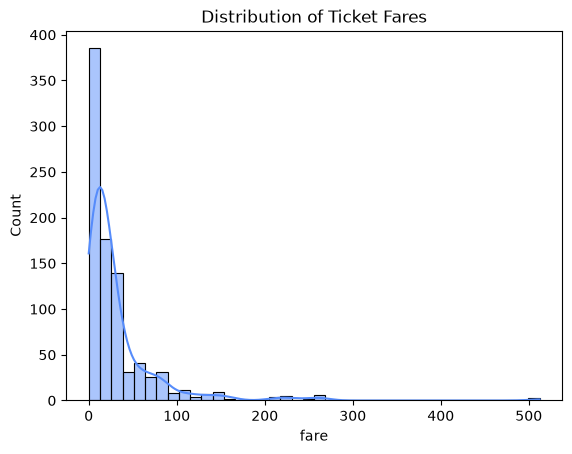

In [74]:
sns.histplot(data=df, x="fare", bins=40, kde=True)
plt.title("Distribution of Ticket Fares")
plt.show()

You may notice a right-skewed distribution: most fares are relatively low, while a smaller number are much higher.

#### 5. Bivariate analysis
Bivariate analysis studies the relationship between two variables. For our project, the most useful question is: **Which passenger characteristics are associated with survival?**

A. Survival by sex

In [77]:
survival_by_sex = df.groupby("sex", observed=True)["survived"].mean() * 100
print(survival_by_sex.round(2))

sex
female    74.20
male      18.89
Name: survived, dtype: float64


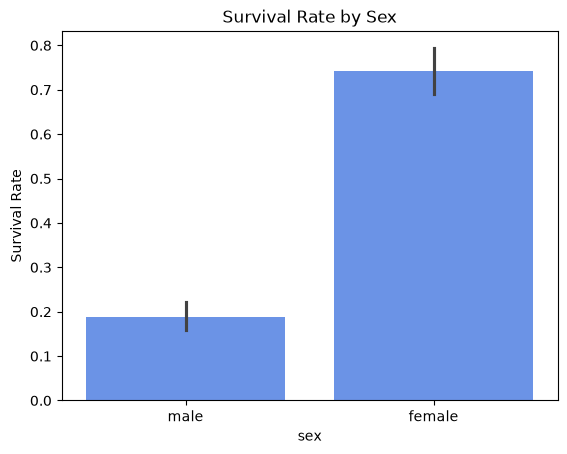

In [78]:
sns.barplot(data=df, x="sex", y="survived")
plt.title("Survival Rate by Sex")
plt.ylabel("Survival Rate")
plt.show()

Because `survived` contains zeros and ones, its mean gives the survival proportion.

In this dataset, the survival rate was approximately 74% for females and 19% for males. This is a substantial association in the historical passenger data, not evidence that sex alone caused the outcome.

B. Survival by passenger class

In [80]:
survival_by_class = (
    df.groupby("class", observed=True)["survived"]
      .mean()
      .mul(100)
)

print(survival_by_class.round(2))

class
First     62.96
Second    47.28
Third     24.24
Name: survived, dtype: float64


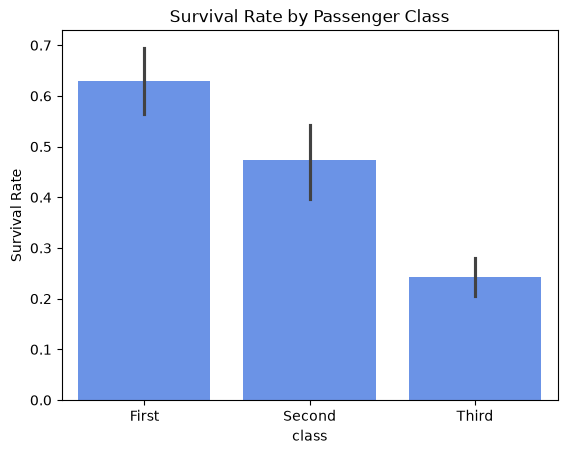

In [81]:
sns.barplot(data=df, x="class", y="survived")
plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

Investigate whether survival rates differ between First, Second, and Third class.

This can help determine whether `pclass` is a useful predictive feature.

C. Survival by age

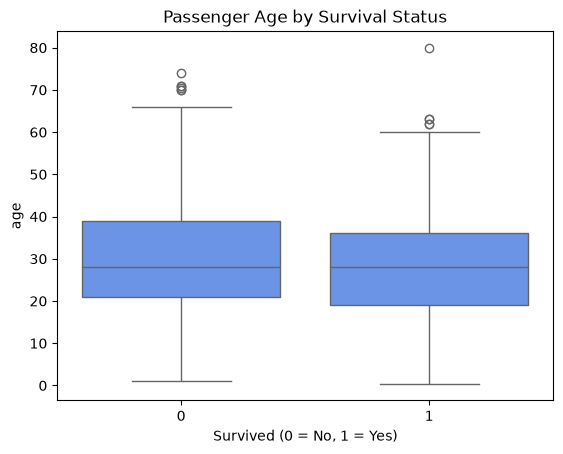

In [82]:
sns.boxplot(data=df, x="survived", y="age")
plt.title("Passenger Age by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

Compare the age distributions of survivors and non-survivors.

A boxplot helps you examine the median, spread, and potential outliers. It does not, by itself, tell you whether age is a strong predictor.

D. Survival by fare

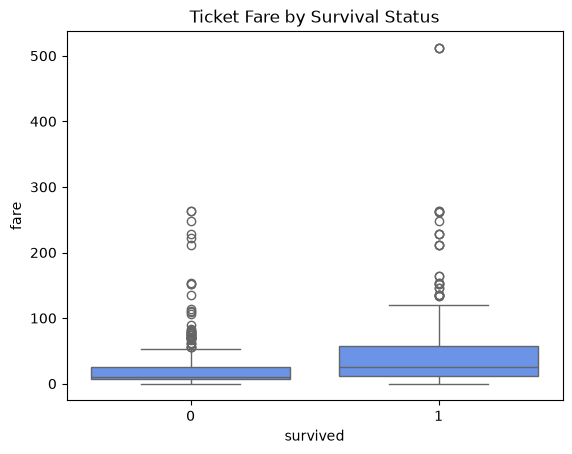

In [83]:
sns.boxplot(data=df, x="survived", y="fare")
plt.title("Ticket Fare by Survival Status")
plt.show()

Ask yourself: **did survivors tend to have higher ticket fares?**

If they did, fare may provide predictive information. However, fare and passenger class are related, so interpret them together.

#### 6. Multivariate analysis
Now examine multiple features together.

A. Survival by sex and passenger class

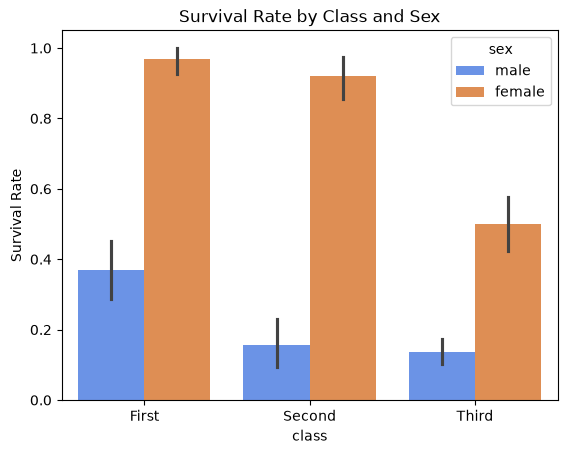

In [84]:
sns.barplot(
    data=df,
    x="class",
    y="survived",
    hue="sex"
)

plt.title("Survival Rate by Class and Sex")
plt.ylabel("Survival Rate")
plt.show()

This visualization helps answer two questions simultaneously:
- Did survival rates differ by passenger class?
- Did the relationship between sex and survival vary across classes?

This is more informative than looking at either feature in isolation.

B. Correlation heatmap

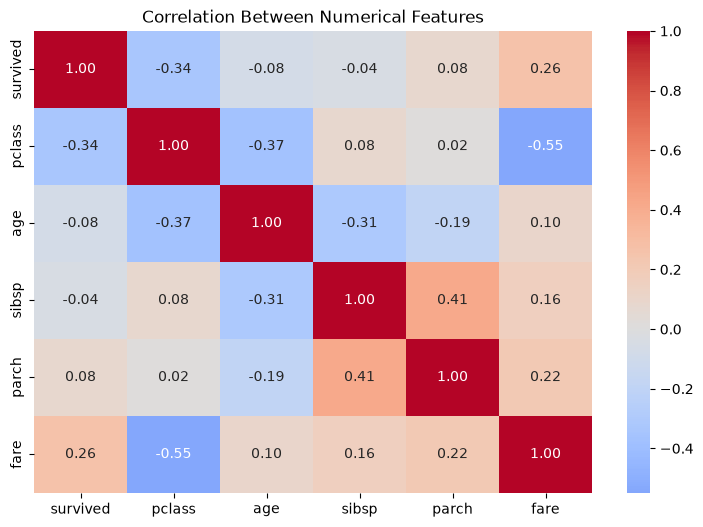

In [85]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numerical Features")
plt.show()

Interpret the heatmap by looking for relationships involving survived.
- A positive correlation means two numerical variables tend to increase together.
- A negative correlation means one tends to decrease as the other increases.
- A correlation near zero indicates little linear association.

**Important**: Correlation does not establish causation. Also, pclass is coded numerically, but it represents an ordered category, so its correlation should be interpreted with care.

#### 7. Detect outliers
Use the Interquartile Range (IQR) method to identify potential outliers in `age` and `fare`.

In [86]:
for column in ["age", "fare"]:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} potential outliers")

age: 11 potential outliers
fare: 116 potential outliers


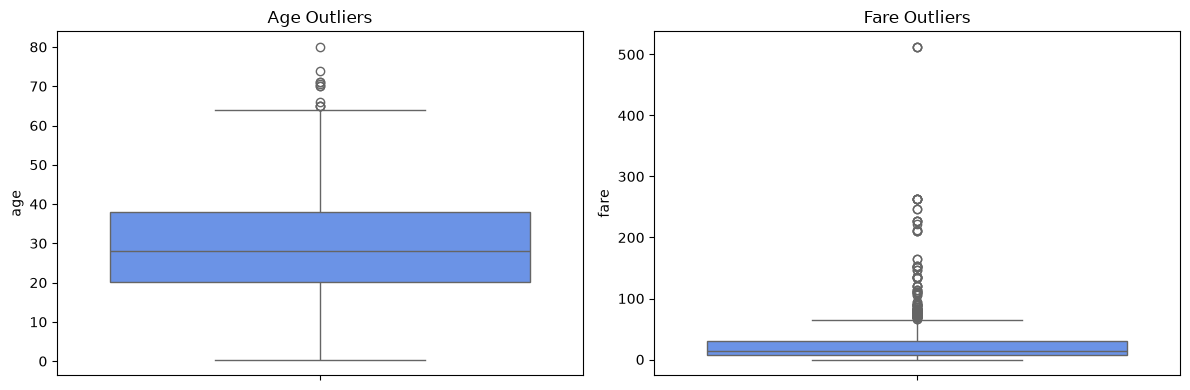

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, y="age", ax=axes[0])
axes[0].set_title("Age Outliers")

sns.boxplot(data=df, y="fare", ax=axes[1])
axes[1].set_title("Fare Outliers")

plt.tight_layout()
plt.show()

An outlier is not automatically an error. Some passengers genuinely paid much higher fares, and unusual ages may be valid. Investigate the records before deciding how to handle them.

## 9. Final EDA Findings

| Question | Finding |
|---|---|
| How many passengers are recorded? | 891 |
| What is the overall survival rate? | About 38.4% |
| Which feature has the most missing values? | `deck` |
| Which other features have missing values? | `age`, `embarked`, `embark_town` |
| Is survival associated with sex? | Yes, strongly |
| Is survival associated with passenger class? | Yes |
| Are potential outliers worth investigating? | Yes, especially for fares |

## 10. Prepare for Machine Learning

| Step | Description |
|---|---|
| Target variable | `survived` |
| Potential features | `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked` |
| Missing values | Handle missing values using a strategy fitted on the training data. |
| Categorical variables | Encode categorical features appropriately. |
| Data leakage | Do not use `alive`, as it directly duplicates the target information. |
| Redundant features | Avoid using `class` alongside `pclass` unless redundancy is intentional. |
| Train-test split | Split the dataset into training and testing sets, preferably using stratification on the target. |
| Model evaluation | Evaluate the trained model on the held-out test set. |
